![Banner](../images/09_13_banner_rs_soil_moisture.png)

# Python Environment and Data Access

A daily SMAP L3 Enhanced file is about 660 MB of global data; a SMOS-SMAP file is 1.6 GB. For a
study area the size of Iowa only a few thousand of the millions of cells are needed. This
notebook shows how GeoLattice reaches each product without downloading the world: NASA OPeNDAP
subsetting for SMAP L3, the Harmony subsetting service for SMAP L4, HTTP range reads of
uncompressed HDF5 for SMOS, the CEDA THREDDS server for ESA CCI, the Open-Meteo archive for
ERA5-Land and the Planetary Computer STAC catalogue for Sentinel-1. Every reader returns a tidy
`xarray.Dataset`, and the chapter helper `sm_data` caches each cube so that later notebooks load it
in one line.

## Overview

### Accounts and credentials

| Source | Account | Where the credential lives |
|---|---|---|
| NASA Earthdata (NSIDC, ASF, GES DISC) | free Earthdata Login | `~/.netrc` (`machine urs.earthdata.nasa.gov login ... password ...`) or `EARTHDATA_USERNAME`/`EARTHDATA_PASSWORD` |
| Microsoft Planetary Computer | none (signed URLs) | handled by `planetary_computer` |
| CEDA (ESA CCI), Open-Meteo, SoilGrids, NOAA USCRN, NRCS SCAN, USGS NWIS | none | |

Credentials never go into a notebook. Some NASA data centres (GES DISC, for AMSR2 LPRM and GLDAS)
also require approving their application once in the Earthdata Login profile.

### Ways to read only what is needed

| Method | How it works | Used for |
|---|---|---|
| OPeNDAP (DAP4) | the server cuts an array by index ranges and returns a small NetCDF | SMAP L3 and L3 Enhanced |
| Harmony | NASA's asynchronous subsetting service: one job subsets hundreds of granules by bbox and variable | SMAP L4 |
| HTTP range reads | `h5py` on a remote file object reads only the bytes of the requested rows (works for uncompressed or small-chunked HDF5) | SMOS-SMAP (NSIDC-0800) |
| THREDDS (DAP2) | constrained ASCII requests per daily file | ESA CCI |
| Web API | JSON time series at grid points | ERA5-Land (Open-Meteo) |
| STAC plus cloud-optimized GeoTIFF | catalogue search, then windowed reads of COGs | Sentinel-1 RTC, Sentinel-2, MODIS, DEM, land cover |

### EASE-Grid 2.0

SMAP and SMOS-SMAP use the global cylindrical EASE-Grid 2.0 (EPSG:6933): an equal-area grid whose
cells are exactly 36.03, 9.008, 3.003 or 1.001 km wide and whose origin is the centre of the map.
A cell's row and column follow from the projected coordinates, so an AOI is a block of rows and
columns, which is what OPeNDAP needs.

## Data Access with GeoLattice

| Function | Purpose |
|---|---|
| `sm.search_product(name, aoi, dates)` | granules of a product (CMR for NASA, daily URLs for ESA CCI) |
| `sm.open_product(name, aoi, dates, cache=)` | subset and read in one call, optionally cached |
| `sm.ease2_grid`, `sm.ease2_index` | EASE-Grid 2.0 coordinates and cell indices |
| `sm.read_era5_land` | ERA5-Land soil water from Open-Meteo |
| `sm.daily_cube`, `sm.harmonize` | merge overpasses, regrid products onto one grid |
| `sm.to_cache` | NetCDF, Zarr or COG output |

### Learning objectives

1. Find granules of NASA soil moisture products and read their metadata.
2. Compute EASE-Grid 2.0 rows and columns for an AOI and for station points.
3. Read one week of SMAP, SMOS, ESA CCI and ERA5-Land for Iowa, transferring only the AOI.
4. Merge AM and PM overpasses and put several products on one grid.
5. Write cubes to NetCDF, Zarr and cloud-optimized GeoTIFF.

### Data

| Dataset | Content |
|---|---|
| SMAP L3 Enhanced, SMOS-SMAP (NSIDC-0800), ESA CCI COMBINED, ERA5-Land | first week of June 2024 over the central Iowa field site |
| Sentinel-1 RTC catalogue | scenes over the field site in 2019 |

### Contents

- Setup
- Finding granules
- EASE-Grid 2.0 cells of the study area
- One week of four products
- Merging overpasses and regridding
- Writing NetCDF, Zarr and COG
- The chapter cache
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.soil_moisture as sm  # soil moisture physics, products, retrieval and validation
import sm_data as sd  # chapter helper: subsets, downloads and caches the data

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

import time  # timing
AOI = sd.IOWA["bbox"]  # central Iowa field site (lon/lat)
WEEK = ("2024-06-01", "2024-06-07")  # one week
print("AOI", AOI)  # area

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_13_soil_moisture
AOI (-93.9, 41.8, -93.3, 42.2)


## Finding granules

`sm.search_product` queries CMR through `earthaccess` (the login is read from `~/.netrc`). Each
granule record has its file name, size, time and links, including the OPeNDAP endpoint.

In [2]:
gran = {name: sm.search_product(name, AOI, WEEK) for name in ("SMAP_L3_E", "SMAP_L4", "SMOS_SMAP_L3")}  # one week each
for name, g in gran.items():  # summary per product
    sizes = [x.size() for x in g]  # file sizes (MB)
    print(f"{name:13s} {len(g):3d} granules, {np.mean(sizes):7.1f} MB each, first: {g[0]['umm']['GranuleUR']}")  # counts and sizes
links = [u["URL"] for u in gran["SMAP_L3_E"][0]["umm"]["RelatedUrls"] if u["URL"].startswith("https")]  # access links
print("\n".join(links[:4]))  # direct download, metadata and OPeNDAP

SMAP_L3_E       7 granules,   656.3 MB each, first: SMAP_L3_SM_P_E_20240601_R19240_001.h5
SMAP_L4        57 granules,   143.9 MB each, first: SMAP_L4_SM_gph_20240531T223000_Vv8012_001.h5_u9loH5HD
SMOS_SMAP_L3    7 granules,  1624.5 MB each, first: NSIDC-0800_SMOS-SMAP-L3_20240601_V02.0.h5_XVyyMxXc
https://data.nsidc.earthdatacloud.nasa.gov/nsidc-cumulus-prod-protected/SMAP/SPL3SMP_E/006/2024/06/01/SMAP_L3_SM_P_E_20240601_R19240_001.h5
https://data.nsidc.earthdatacloud.nasa.gov/nsidc-cumulus-prod-public/SMAP/SPL3SMP_E/006/2024/06/01/SMAP_L3_SM_P_E_20240601_R19240_001.h5.iso.xml
https://data.nsidc.earthdatacloud.nasa.gov/nsidc-cumulus-prod-protected/SMAP/SPL3SMP_E/006/2024/06/01/SMAP_L3_SM_P_E_20240601_R19240_001.qa
https://data.nsidc.earthdatacloud.nasa.gov/s3credentials


A week of SMAP L3 Enhanced is seven global files of 656 MB; SMAP L4 is 57 files (eight 3-hourly
analyses per day) of 144 MB; SMOS-SMAP is seven files of 1.6 GB. Downloading them for an AOI of 42
cells would move about 24 GB for a few kilobytes of data.

## EASE-Grid 2.0 cells of the study area

In [3]:
g9 = sm.ease2_grid("EASE2_M09km", aoi=AOI)  # 9 km cells covering the AOI
g36 = sm.ease2_grid("EASE2_M36km", aoi=AOI)  # 36 km cells
print(f"9 km: rows {int(g9.row.min())} to {int(g9.row.max())}, cols {int(g9.col.min())} to {int(g9.col.max())} ({g9.sizes['y']} x {g9.sizes['x']} cells)")  # window
print(f"36 km: {g36.sizes['y']} x {g36.sizes['x']} cells")  # coarse window
r, c = sm.ease2_index(sd.STATIONS.lat.values, sd.STATIONS.lon.values, "EASE2_M09km")  # station cells
display(sd.STATIONS.assign(row_9km=r, col_9km=c))  # station positions on the grid

9 km: rows 265 to 270, cols 922 to 928 (6 x 7 cells)
36 km: 2 x 3 cells


,network,id,lon,lat,row_9km,col_9km
station,,,,,,
USCRN Des Moines 17 E,USCRN,IA_Des_Moines_17_E,-93.28610,41.5564,272,928
SCAN Ames,SCAN,2031:IA:SCAN,-93.72977,42.0136,267,924


## One week of four products

Each call transfers only the AOI. The timings include the server work.

In [4]:
cubes, rows = {}, []  # cubes and timing table
for name, kw in (("SMAP_L3_E", {}), ("SMOS_SMAP_L3", {"variables": ("soil_moisture", "retrieval_qual_flag")}),
                 ("ESA_CCI", {"product": "COMBINED"})):  # three gridded products
    t0 = time.time()  # start
    cubes[name] = sm.open_product(name, AOI, WEEK, **kw)  # subset and read
    rows.append({"product": name, "seconds": round(time.time() - t0, 1), "dims": dict(cubes[name].sizes),
                 "MB in memory": round(cubes[name].nbytes / 2**20, 2)})  # what came back
t0 = time.time()  # ERA5-Land at the two stations
cubes["ERA5_LAND"] = sm.read_era5_land(None, WEEK, points=list(zip(sd.STATIONS.lon, sd.STATIONS.lat)))  # three layers
rows.append({"product": "ERA5_LAND (2 points)", "seconds": round(time.time() - t0, 1), "dims": dict(cubes["ERA5_LAND"].sizes),
             "MB in memory": round(cubes["ERA5_LAND"].nbytes / 2**20, 3)})  # timing
display(pd.DataFrame(rows).set_index("product"))  # summary
print(cubes["SMAP_L3_E"])  # the SMAP cube: time, overpass, y, x

,seconds,dims,MB in memory
product,,,
SMAP_L3_E,6.7,"{'time': 7, 'overpass': 2, 'y': 6, 'x': 7}",0.02
SMOS_SMAP_L3,73.5,"{'time': 7, 'overpass': 2, 'y': 6, 'x': 7}",0.00
ESA_CCI,1.1,"{'time': 7, 'lat': 2, 'lon': 3}",0.00
ERA5_LAND (2 points),0.9,"{'time': 7, 'point': 2}",0.00


<xarray.Dataset> Size: 17kB
Dimensions:                   (time: 7, overpass: 2, y: 6, x: 7)
Coordinates:
  * time                      (time) datetime64[us] 56B 2024-06-01 ... 2024-0...
  * overpass                  (overpass) <U2 16B 'AM' 'PM'
  * y                         (y) float64 48B 4.923e+06 4.914e+06 ... 4.878e+06
    row                       (y) int64 48B 265 266 267 268 269 270
  * x                         (x) float64 56B -9.058e+06 ... -9.004e+06
    col                       (x) int64 56B 922 923 924 925 926 927 928
    lat                       (y, x) float64 336B 42.23 42.23 ... 41.76 41.76
    lon                       (y, x) float64 336B -93.87 -93.78 ... -93.31
    spatial_ref               int64 8B 0
Data variables:
    sm                        (time, overpass, y, x) float32 2kB 0.2411 ... nan
    retrieval_qual_flag       (time, overpass, y, x) uint16 1kB 0 0 0 ... 7 7 7
    surface_flag              (time, overpass, y, x) uint16 1kB 0 0 ... 2047
    vegetation_

The SMAP cube has `time`, `overpass` (AM descending at 6 am local time, PM ascending at 6 pm), `y`
and `x` in EPSG:6933, with soil moisture as `sm` and the quality flags and ancillary layers that
the retrieval used. A week of data is about 20 kB in memory; the OPeNDAP subset of SMAP took about 7
seconds and the range reads of the 1.6 GB SMOS-SMAP files about 75 seconds.

## Merging overpasses and regridding

`sm.daily_cube` keeps the AM retrieval and fills it with PM where the morning is missing (the
morning is preferred because the soil and canopy temperatures are closest then). `sm.harmonize`
puts products on one grid; here everything goes onto the 9 km EASE grid, with area averaging.

SMAP cells filled from PM: 20%


,SMAP,SMOS,CCI
time,,,
2024-06-01,0.226,0.181,0.282
2024-06-02,NaN,0.132,0.283
2024-06-03,0.157,NaN,0.278
2024-06-04,0.154,0.155,0.275
2024-06-05,0.190,NaN,0.304
2024-06-06,0.226,0.220,0.311
2024-06-07,NaN,0.173,0.273


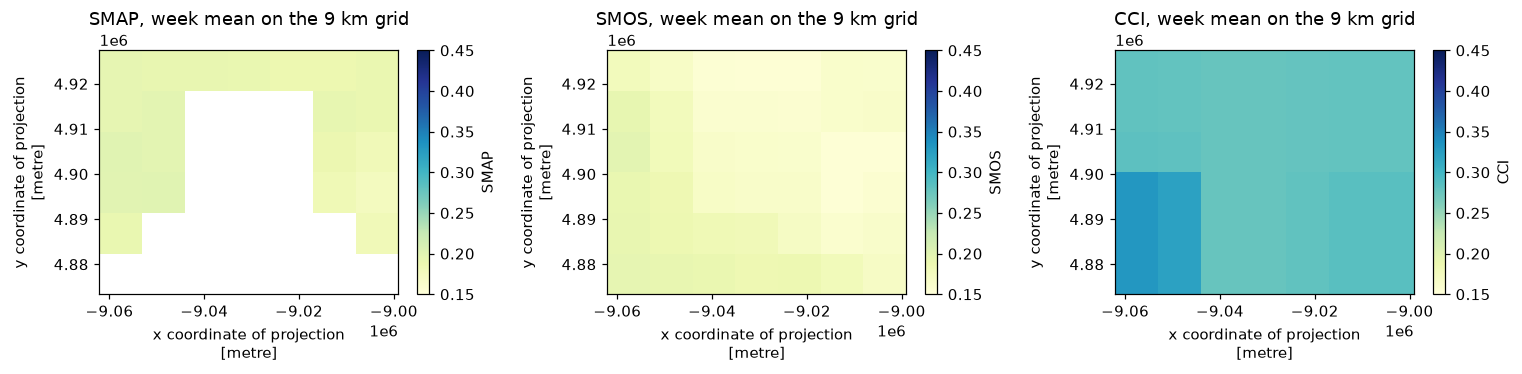

In [5]:
smap = sm.daily_cube(sm.mask_quality(cubes["SMAP_L3_E"]))  # recommended quality, AM first
smos = sm.daily_cube(sm.mask_quality(cubes["SMOS_SMAP_L3"]))  # same for SMOS
used = smap.overpass_used.where(smap.overpass_used >= 0)  # 0 = AM, 1 = PM
print(f"SMAP cells filled from PM: {float((used == 1).sum() / used.notnull().sum()):.0%}")  # share of PM
h = sm.harmonize({"SMAP": smap.sm, "SMOS": smos.sm, "CCI": cubes["ESA_CCI"].sm}, target=smap.sm)  # one grid
display(h.mean(("y", "x")).to_dataframe()[["SMAP", "SMOS", "CCI"]].round(3))  # AOI means per day
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))  # maps on the common grid
for a, v in zip(ax, ("SMAP", "SMOS", "CCI")):  # each product
    h[v].mean("time").plot(ax=a, vmin=0.15, vmax=0.45, cmap="YlGnBu"); a.set_title(f"{v}, week mean on the 9 km grid")  # map
plt.tight_layout(); plt.show()  # draw

On the common 9 km grid SMAP and SMOS give similar AOI means (0.15 to 0.23 m3 m-3) on the days both
observed, and they fill each other's gaps; ESA CCI, rescaled to a land model climatology, is about
0.08 m3 m-3 wetter. A fifth of the SMAP cells came from the evening pass.

## Writing NetCDF, Zarr and COG

NetCDF suits whole cubes, Zarr suits large cubes read in chunks, and cloud-optimized GeoTIFFs suit
single maps that GIS software and web viewers read directly.

In [6]:
out = OUT / "access_demo"  # demo folder
paths = {fmt: sm.to_cache(smap[["sm"]], str(out / f"smap_week.{ext}"), fmt=fmt) for fmt, ext in (("netcdf", "nc"), ("zarr", "zarr"), ("cog", "cog"))}  # three formats
for fmt, p in paths.items():  # sizes on disk
    size = sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file()) if Path(p).is_dir() else Path(p).stat().st_size  # bytes
    print(f"{fmt:7s} {p}  {size / 1024:.0f} kB")  # path and size
print(xr.open_dataset(paths["netcdf"]).sm.sizes)  # read back

netcdf  outputs/access_demo/smap_week.nc  21 kB
zarr    outputs/access_demo/smap_week.zarr  20 kB
cog     outputs/access_demo/smap_week.cog  3 kB


Frozen({'time': 7, 'y': 6, 'x': 7})


## The chapter cache

`sm_data.py` wraps these calls with fixed study areas and periods and caches each cube under
`Data/08_remote_sensing/08_13_soil_moisture/`. The first call of, for example, `sd.smap_l3e()`
subsets ten years of daily SMAP over the Midwest (about 3,900 OPeNDAP requests, half an hour);
afterwards it opens in a second.

In [7]:
files = sorted(p for p in sd.DATA.rglob("*") if p.is_file())  # cached files
cache = pd.DataFrame({"file": [str(p.relative_to(sd.DATA)) for p in files], "MB": [round(p.stat().st_size / 2**20, 1) for p in files]})  # table
display(cache)  # what the chapter has cached so far
print(f"total {cache.MB.sum():.0f} MB")  # size of the cache

,file,MB
0,boundaries/cb_2023_us_county_500k.zip,11.1
1,boundaries/geoboundaries_BGD_ADM0.geojson,0.1
2,boundaries/geoboundaries_BGD_ADM2.geojson,1.6
3,cci/cci_active_iowa_2015_2024.nc,8.0
4,cci/cci_combined_bangladesh_1979_2024.nc,27.6
5,cci/cci_combined_iowa_2015_2024.nc,7.8
6,cci/cci_passive_iowa_2015_2024.nc,8.0
7,era5_land/era5land_bangladesh_2010_2024_1.0deg...,0.5
8,era5_land/era5land_iowa_2015_2025_0.5deg_l1.nc,1.4
9,era5_land/era5land_stations_2015_2025.nc,0.1


total 1176 MB


## Summary and exercises

- Global soil moisture files are hundreds of megabytes to gigabytes per day, but an AOI needs only
  kilobytes; OPeNDAP, Harmony, HTTP range reads and THREDDS each deliver just the AOI.
- EASE-Grid 2.0 rows and columns follow directly from EPSG:6933 coordinates.
- `sm.open_product` returns tidy cubes with quality layers; `sm.daily_cube` and `sm.harmonize` make
  products comparable on one daily grid.
- NetCDF, Zarr and COG serve different uses; the chapter cache makes every later notebook fast.

**Exercises**

1. Time `sm.open_product("SMAP_L3_E", ...)` for a box twice as wide. Does the time grow with the
   area or with the number of days?
2. Read one week of SMAP L4 with `sm.open_product("SMAP_L4", AOI, WEEK, hours=("013000", "133000"))`
   and plot the diurnal difference of surface soil moisture.
3. Find all Sentinel-1 RTC scenes over the AOI in 2019 with `geolattice.rsense.access.stac_search` and
   count them by relative orbit.